# Etapa 2 — Treinamento e Comparação de Arquiteturas MLP

Objetivo: Treinar 3 arquiteturas de rede neural MLP, comparar métricas e selecionar a melhor.

## Resumo
- **Arquitetura 1**: 32 neurônios (baseline simples)
- **Arquitetura 2**: 64 → 32 neurônios (intermediária)
- **Arquitetura 3**: 128 → 64 → 32 neurônios (complexa)

Todas com camada de saída sigmoide para classificação binária (roubo=1, furto=0).
Métrica de seleção: **F1-score macro em validação, médio em 5 seeds**, com regra de parcimônia (seção 10).
O teste 2025 só confirma a escolha; o teste 2026 fica reservado e não é usado neste notebook.

**Data**: 2026-11-12 (revisão 2026-11-14: correção da tabela, melhor época nos gráficos, seleção com várias seeds)
**Estado**: Implementação Etapa 2

## 1. Importações e configurações

In [1]:
# Importa numpy para operações numéricas e arrays.
import numpy as np
# Importa pandas para manipulação de DataFrames.
import pandas as pd
# Importa matplotlib para gerar gráficos (linhas, scatter, etc.).
import matplotlib.pyplot as plt
# Importa seaborn para melhorar estética dos gráficos e heatmaps.
import seaborn as sns

# Importa PyTorch para construção e treinamento de redes neurais.
import torch
# Importa módulo de camadas (Linear, etc.) do PyTorch.
import torch.nn as nn
# Importa funções de otimização (Adam, etc.).
from torch.optim import AdamW
# Importa DataLoader para iteração em minibatches.
from torch.utils.data import DataLoader, TensorDataset

# Importa funções de métricas do scikit-learn.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
# Importa módulo de carregamento de dados do projeto.
from src.data.loader import carregar_e_preparar
# Importa funções de divisão e consolidação de dados.
from src.data.splitter import preparar_split_2025, preparar_teste_2026
# Importa função de pré-processamento de features.
from src.data.preprocessor import preparar_features
# Importa configurações centrais (paths, sementes, hiperparâmetros).
from src.utils.config import RANDOM_SEED, LEARNING_RATE, EPOCHS, BATCH_SIZE, BEST_MODEL_DIR, EXPERIMENTS_DIR

# Define seed do numpy para reprodutibilidade (mesmas séries aleatórias toda execução).
np.random.seed(RANDOM_SEED)
# Define seed do PyTorch para reprodutibilidade (inicialização de pesos consistente).
torch.manual_seed(RANDOM_SEED)

# Define backend CUDA como padrão se disponível, senão usa CPU.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# Exibe qual dispositivo está sendo usado (GPU ou CPU).
print(f"Dispositivo: {device}")

Dispositivo: cuda


## 2. Carregar e preparar dados

In [2]:
# Carrega dados brutos de 2025 (todos os registros, pode demorar alguns minutos).
# Se quiser teste rápido, adicione: linhas=5000
print("Carregando dados 2025...")
df_2025 = carregar_e_preparar(ano=2025)
# Imprime dimensões e distribuição de classes.
print(f"Carregado: {df_2025.shape[0]:,} registros")
print(f"Furtos: {(df_2025['target']==0).sum():,} | Roubos: {(df_2025['target']==1).sum():,}")

# Carrega dados brutos de 2026 (todos os registros para teste final).
print("\nCarregando dados 2026...")
df_2026 = carregar_e_preparar(ano=2026)
# Imprime dimensões e distribuição de classes.
print(f"Carregado: {df_2026.shape[0]:,} registros")
print(f"Furtos: {(df_2026['target']==0).sum():,} | Roubos: {(df_2026['target']==1).sum():,}")

Carregando dados 2025...
Carregado: 183,798 registros
Furtos: 106,392 | Roubos: 77,406

Carregando dados 2026...
Carregado: 126,567 registros
Furtos: 77,003 | Roubos: 49,564


In [3]:
# Consolida boletins (múltiplas linhas do mesmo NUM_BO → 1 linha) e divide estratificado 70/15/15.
print("Dividindo 2025 em treino/validação/teste...")
train, val, test_2025 = preparar_split_2025(df_2025)
# Imprime tamanhos dos conjuntos de treino, validação e teste.
print(f"Treino: {train.shape[0]:,} | Validação: {val.shape[0]:,} | Teste(2025): {test_2025.shape[0]:,}")

# Consolida boletins de 2026 (sem split, todo o arquivo vira teste final).
print("\nPrparando 2026 como teste final...")
test_2026 = preparar_teste_2026(df_2026)
# Imprime tamanho do teste final.
print(f"Teste(2026): {test_2026.shape[0]:,}")

Dividindo 2025 em treino/validação/teste...
Treino: 113,129 | Validação: 24,242 | Teste(2025): 24,243

Prparando 2026 como teste final...
Teste(2026): 112,192


In [4]:
# Aplica pré-processamento: derivação temporal (dia_semana, mes, hora), encoding, scaling.
# FIT é feito apenas no treino; TRANSFORM é aplicado em validação e teste.
print("Pré-processando features...")

# Fit: ajusta imputação, encoder e scaler nos dados de treino.
X_train, y_train, preprocessor = preparar_features(train, fit=True)
# Transform: aplica transformações do treino em validação (sem readaptar).
X_val, y_val, _ = preparar_features(val, preprocessor=preprocessor, fit=False)
# Transform: aplica transformações do treino em teste(2025) (sem readaptar).
X_test_2025, y_test_2025, _ = preparar_features(test_2025, preprocessor=preprocessor, fit=False)
# Transform: aplica transformações do treino em teste(2026) (sem readaptar).
X_test_2026, y_test_2026, _ = preparar_features(test_2026, preprocessor=preprocessor, fit=False)

# Imprime dimensões dos arrays transformados.
print(f"\nX_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_val: {X_val.shape} | y_val: {y_val.shape}")
print(f"X_test_2025: {X_test_2025.shape} | y_test_2025: {y_test_2025.shape}")
print(f"X_test_2026: {X_test_2026.shape} | y_test_2026: {y_test_2026.shape}")

# Salva número de features para usar na definição das arquiteturas MLP.
n_features = X_train.shape[1]
# Exibe quantas features foram geradas após encoding e derivação.
print(f"\nNúmero de features: {n_features}")

Pré-processando features...

X_train: (113129, 1914) | y_train: (113129,)
X_val: (24242, 1914) | y_val: (24242,)
X_test_2025: (24243, 1914) | y_test_2025: (24243,)
X_test_2026: (112192, 1914) | y_test_2026: (112192,)

Número de features: 1914


## 3. Definir modelos MLP

In [5]:
# Define classe da rede neural MLP (Multilayer Perceptron).
class MLP(nn.Module):
    # Inicializa os parâmetros e camadas da rede.
    def __init__(self, input_size, hidden_sizes, output_size=1, activation='relu', dropout=0.2):
        # Chama construtor da classe pai (nn.Module).
        super(MLP, self).__init__()
        
        # Inicializa lista para armazenar camadas lineares (nn.Linear).
        self.layers = nn.ModuleList()
        # Inicializa lista para armazenar funções de ativação.
        self.activations = nn.ModuleList()
        # Inicializa lista para armazenar camadas de dropout (regularização).
        self.dropouts = nn.ModuleList()
        
        # Define função de ativação conforme parâmetro (default ReLU).
        if activation == 'relu':
            # Cria função ReLU (max(0, x)) para serem usadas entre camadas.
            act_func = nn.ReLU
        else:
            # Se não for ReLU, usa Tanh como alternativa.
            act_func = nn.Tanh
        
        # Constrói camadas ocultas: entrada → hidden_1 → hidden_2 → ... → hidden_n.
        # Itera sobre cada tamanho de camada oculta em hidden_sizes.
        for i, hidden_size in enumerate(hidden_sizes):
            # Se é a primeira camada, entrada tem dimensão input_size; senão, input_size = hidden_sizes[i-1].
            if i == 0:
                # Cria camada Linear: input_size → hidden_size.
                self.layers.append(nn.Linear(input_size, hidden_size))
            else:
                # Cria camada Linear: hidden_sizes[i-1] → hidden_size.
                self.layers.append(nn.Linear(hidden_sizes[i-1], hidden_size))
            # Adiciona função de ativação (ReLU ou Tanh).
            self.activations.append(act_func())
            # Adiciona camada de Dropout com taxa padrão (evita overfitting).
            self.dropouts.append(nn.Dropout(dropout))
        
        # Cria camada de saída: última camada oculta → output_size (1 para binária).
        if len(hidden_sizes) > 0:
            # Se há camadas ocultas, saída vem da última oculta.
            self.output_layer = nn.Linear(hidden_sizes[-1], output_size)
        else:
            # Se não há ocultas (caso trivial), saída vem direto da entrada.
            self.output_layer = nn.Linear(input_size, output_size)
    
    # Define o passo forward (propagação dos dados pela rede).
    def forward(self, x):
        # Itera sobre cada camada oculta, ativação e dropout.
        for layer, activation, dropout in zip(self.layers, self.activations, self.dropouts):
            # Aplica a camada linear: matriz × entrada + viés.
            x = layer(x)
            # Aplica função de ativação (ReLU ou Tanh).
            x = activation(x)
            # Aplica Dropout (zeroa alguns neurônios aleatoriamente durante treino).
            x = dropout(x)
        # Aplica camada de saída (sem ativação aqui; será usada sigmoide na perda).
        x = self.output_layer(x)
        # Retorna saída da rede.
        return x

# Exibe classe MLP definida.
print("Classe MLP definida com sucesso.")

Classe MLP definida com sucesso.


## 4. Funções de treino e avaliação

In [6]:
# Define função para treinar a rede por 1 época (passada pelos dados).
def treinar_epoca(model, train_loader, loss_fn, optimizer, device):
    # Define modelo em modo treino (ativa Dropout e BatchNorm específicas de treino).
    model.train()
    # Inicializa acumulador de perda total da época.
    total_loss = 0
    # Inicializa contador de amostras processadas.
    total_samples = 0
    
    # Itera sobre cada minibatch do DataLoader.
    for X_batch, y_batch in train_loader:
        # Move X_batch para o dispositivo (GPU ou CPU).
        X_batch = X_batch.to(device)
        # Move y_batch para o dispositivo (GPU ou CPU).
        y_batch = y_batch.to(device).float().unsqueeze(1)  # Redimensiona para (batch_size, 1).
        
        # Zera gradientes do otimizador (evita acúmulo de gradientes de batches anteriores).
        optimizer.zero_grad()
        # Propagação forward: passa X_batch pela rede.
        y_pred = model(X_batch)
        # Calcula perda entre predições e rótulos reais.
        loss = loss_fn(y_pred, y_batch)
        # Propagação backward: calcula gradientes (derivadas).
        loss.backward()
        # Atualiza pesos com base nos gradientes (Adam).
        optimizer.step()
        
        # Acumula perda do batch (desacopla do grafo computacional com .item()).
        total_loss += loss.item() * X_batch.size(0)
        # Incrementa contador de amostras pelo tamanho do batch.
        total_samples += X_batch.size(0)
    
    # Calcula perda média da época (total_loss / total_samples).
    avg_loss = total_loss / total_samples
    # Retorna perda média.
    return avg_loss

# Define função para avaliar a rede sem atualizar pesos (modo inferência).
def avaliar(model, data_loader, loss_fn, device):
    # Define modelo em modo avaliação (desativa Dropout e BatchNorm).
    model.eval()
    # Inicializa acumulador de perda total.
    total_loss = 0
    # Inicializa lista para armazenar todas as predições.
    y_preds = []
    # Inicializa lista para armazenar todos os rótulos reais.
    y_trues = []
    
    # Desativa cálculo de gradientes (economiza memória e acelera).
    with torch.no_grad():
        # Itera sobre cada minibatch do DataLoader.
        for X_batch, y_batch in data_loader:
            # Move X_batch para o dispositivo.
            X_batch = X_batch.to(device)
            # Move y_batch para o dispositivo e redimensiona.
            y_batch = y_batch.to(device).float().unsqueeze(1)
            
            # Propagação forward: passa X_batch pela rede.
            y_pred = model(X_batch)
            # Calcula perda do batch.
            loss = loss_fn(y_pred, y_batch)
            # Acumula perda.
            total_loss += loss.item() * X_batch.size(0)
            
            # Converte predições para 0 ou 1 (threshold=0.5) e move para CPU.
            y_pred_binary = (y_pred > 0).float().squeeze().cpu().numpy()
            # Converte rótulos reais para numpy e move para CPU.
            y_batch_np = y_batch.squeeze().cpu().numpy()
            
            # Adiciona predições à lista.
            y_preds.extend(y_pred_binary if y_pred_binary.ndim > 0 else [y_pred_binary])
            # Adiciona rótulos reais à lista.
            y_trues.extend(y_batch_np if y_batch_np.ndim > 0 else [y_batch_np])
    
    # Calcula perda média de validação/teste.
    avg_loss = total_loss / len(data_loader.dataset)
    # Converte listas para arrays numpy.
    y_preds = np.array(y_preds)
    y_trues = np.array(y_trues)
    
    # Calcula acurácia: proporção de acertos.
    acc = accuracy_score(y_trues, y_preds)
    # Calcula precisão: de quantas vezes o modelo previu "1", quantas acertou.
    prec = precision_score(y_trues, y_preds, zero_division=0)
    # Calcula recall: de quantas amostras reais com "1", quantas o modelo acertou.
    rec = recall_score(y_trues, y_preds, zero_division=0)
    # Calcula F1 macro: média não ponderada de F1 por classe (bom para desequilíbrio).
    f1 = f1_score(y_trues, y_preds, average='macro', zero_division=0)
    
    # Retorna perda média, acurácia, precisão, recall, F1, predições e rótulos reais.
    return avg_loss, acc, prec, rec, f1, y_preds, y_trues

class EarlyStopping:
    def __init__(self, patience=8, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float('inf')
        self.counter = 0
        self.best_state = None
        self.stopped_epoch = 0

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            self.best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                return True  # sinaliza para parar
        return False

    def restore(self, model):
        if self.best_state:
            model.load_state_dict(self.best_state)
            print(f"  ↩️ Pesos restaurados (melhor val_loss={self.best_loss:.4f})")


# === NOVO: Função de treino com early stopping ===
def treinar_com_early_stopping(model, train_loader, val_loader, loss_fn, optimizer, 
                                device, epochs=100, patience=8, log_every=5):
    """Treina com early stopping; retorna (model, history_dict)."""
    model.to(device)
    early = EarlyStopping(patience=patience)
    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
    # Guarda a menor val_loss já vista, para destacar épocas em que houve melhora.
    best_val_loss_seen = float('inf')
    # Inicializa a época da melhor val_loss.
    best_epoch_seen = 0

    for epoch in range(1, epochs + 1):
        # Treino
        train_loss = treinar_epoca(model, train_loader, loss_fn, optimizer, device)
        # Validação
        val_loss, val_acc, _, _, val_f1, _, _ = avaliar(model, val_loader, loss_fn, device)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['val_f1'].append(val_f1)

        # Log
        
        print(f"Época {epoch:3d}/{epochs} | Train Loss: {train_loss:.4f} | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | Val F1: {val_f1:.4f}")
        
        # Atualiza o early stopping e guarda se a paciência acabou.
        parar = early(val_loss, model)
        # Contador zerado = o early stopping aceitou esta época como melhor (mesmo critério com min_delta usado para salvar os pesos).
        if early.counter == 0:
            # Registra a época cujos pesos serão restaurados.
            best_epoch_seen = epoch
            # Registra a val_loss dessa época.
            best_val_loss_seen = val_loss

        # Interrompe o treino quando a paciência se esgota.
        if parar:
            print(f"\n  ⏹ Early stopping na época {epoch} (patience={patience})")
            break

    early.restore(model)
    # Guarda no histórico a época dos pesos restaurados (usada na tabela e nos gráficos).
    history['best_epoch'] = best_epoch_seen
    # Exibe o resumo da melhor época encontrada durante o treino.
    print(f"  → Melhor época: {best_epoch_seen} (val_loss={best_val_loss_seen:.4f})")
    return model, history
# Exibe funções definidas.
print("Funções de treino e avaliação definidas.")

Funções de treino e avaliação definidas.


## 5. Treinar Arquitetura 1: 32 neurônios

In [7]:
# Define arquitetura 1: entrada → 32 → saída (sigmoide na perda).
print("\n" + "="*60)
print("ARQUITETURA 1: 32 neurônios (baseline simples)")
print("="*60)

# Cria instância do modelo com 1 camada oculta de 32 neurônios.
model_1 = MLP(input_size=n_features, hidden_sizes=[32], output_size=1)
# Move modelo para o dispositivo (GPU ou CPU).
model_1 = model_1.to(device)
# Exibe arquitetura do modelo.
print(model_1)

# Define função de perda: Binary Cross Entropy (para classificação binária com sigmoide integrada).
loss_fn = nn.BCEWithLogitsLoss()
# Define otimizador Adam com taxa de aprendizado LEARNING_RATE (1e-3).
optimizer_1 = AdamW(model_1.parameters(), lr=LEARNING_RATE, weight_decay = 1e-4)

# Cria TensorDataset a partir de X_train e y_train (arrays numpy → tensores PyTorch).
train_dataset = TensorDataset(torch.tensor(X_train, dtype=torch.float32),
                              torch.tensor(y_train, dtype=torch.float32))
# Cria DataLoader com batch_size e shuffle=True (embaralha dados a cada época).
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

# Cria TensorDataset para validação.
val_dataset = TensorDataset(torch.tensor(X_val, dtype=torch.float32),
                            torch.tensor(y_val, dtype=torch.float32))
# Cria DataLoader sem shuffle para validação.
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Inicializa listas para armazenar histórico de perda e métricas por época.
train_losses_1 = []
val_losses_1 = []
val_accs_1 = []
val_f1s_1 = []

# Treina por EPOCHS (50 épocas, conforme config.py).
# Treina com Early Stopping (patience=10, epochs=100 como teto)
model_1, history_1 = treinar_com_early_stopping(
    model_1, train_loader, val_loader, loss_fn, optimizer_1,
    device=device, epochs=50, patience=10, log_every=1
)

# Extrai listas do history para compatibilidade com resto do notebook
train_losses_1 = history_1['train_loss']
val_losses_1   = history_1['val_loss']
val_accs_1     = history_1['val_acc']
val_f1s_1      = history_1['val_f1']

# Avalia no conjunto de teste (2025).
test_loss_1, test_acc_1, test_prec_1, test_rec_1, test_f1_1, _, _ = avaliar(model_1, 
    DataLoader(TensorDataset(torch.tensor(X_test_2025, dtype=torch.float32),
                             torch.tensor(y_test_2025, dtype=torch.float32)),
               batch_size=BATCH_SIZE, shuffle=False),
    loss_fn, device)
# Exibe resultado final no teste.
print(f"\n[TESTE 2025] Loss: {test_loss_1:.4f} | Acc: {test_acc_1:.4f} | F1: {test_f1_1:.4f}")

val_loss_final_1, val_acc_final_1, _, _, val_f1_final_1, _, _ = avaliar(model_1, val_loader, loss_fn, device)


ARQUITETURA 1: 32 neurônios (baseline simples)
MLP(
  (layers): ModuleList(
    (0): Linear(in_features=1914, out_features=32, bias=True)
  )
  (activations): ModuleList(
    (0): ReLU()
  )
  (dropouts): ModuleList(
    (0): Dropout(p=0.2, inplace=False)
  )
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
)
Época   1/50 | Train Loss: 0.4818 | Val Loss: 0.4113 | Val Acc: 0.8123 | Val F1: 0.8050
Época   2/50 | Train Loss: 0.3998 | Val Loss: 0.3983 | Val Acc: 0.8214 | Val F1: 0.8130
Época   3/50 | Train Loss: 0.3920 | Val Loss: 0.3932 | Val Acc: 0.8277 | Val F1: 0.8187
Época   4/50 | Train Loss: 0.3885 | Val Loss: 0.3904 | Val Acc: 0.8292 | Val F1: 0.8195
Época   5/50 | Train Loss: 0.3858 | Val Loss: 0.3886 | Val Acc: 0.8303 | Val F1: 0.8203
Época   6/50 | Train Loss: 0.3839 | Val Loss: 0.3874 | Val Acc: 0.8305 | Val F1: 0.8205
Época   7/50 | Train Loss: 0.3826 | Val Loss: 0.3864 | Val Acc: 0.8314 | Val F1: 0.8217
Época   8/50 | Train Loss: 0.3816 | Val Loss: 0.3856 

## 6. Treinar Arquitetura 2: 64 → 32 neurônios

In [8]:
# Define arquitetura 2: entrada → 64 → 32 → saída (mais complexa que Arq1).
print("\n" + "="*60)
print("ARQUITETURA 2: 64 → 32 neurônios (intermediária)")
print("="*60)

# Cria instância do modelo com 2 camadas ocultas.
model_2 = MLP(input_size=n_features, hidden_sizes=[64, 32], output_size=1)
# Move modelo para dispositivo.
model_2 = model_2.to(device)
# Exibe arquitetura.
print(model_2)

# Define otimizador Adam para modelo 2.
optimizer_2 = AdamW(model_2.parameters(), lr=LEARNING_RATE, weight_decay = 1e-4)

# Inicializa históricos de perda e métricas.
train_losses_2 = []
val_losses_2 = []
val_accs_2 = []
val_f1s_2 = []

# Treina por EPOCHS.
# Treina com Early Stopping (patience=10, epochs=100 como teto)
model_2, history_2 = treinar_com_early_stopping(
    model_2, train_loader, val_loader, loss_fn, optimizer_2,
    device=device, epochs=50, patience=10, log_every=1
)

# Extrai listas do history para compatibilidade com resto do notebook
train_losses_2 = history_2['train_loss']
val_losses_2   = history_2['val_loss']
val_accs_2     = history_2['val_acc']
val_f1s_2      = history_2['val_f1']

# Avalia no conjunto de teste (2025).
test_loss_2, test_acc_2, test_prec_2, test_rec_2, test_f1_2, _, _ = avaliar(model_2,
    DataLoader(TensorDataset(torch.tensor(X_test_2025, dtype=torch.float32),
                             torch.tensor(y_test_2025, dtype=torch.float32)),
               batch_size=BATCH_SIZE, shuffle=False),
    loss_fn, device)
# Exibe resultado final.
print(f"\n[TESTE 2025] Loss: {test_loss_2:.4f} | Acc: {test_acc_2:.4f} | F1: {test_f1_2:.4f}")

val_loss_final_2, val_acc_final_2, _, _, val_f1_final_2, _, _ = avaliar(model_2, val_loader, loss_fn, device)


ARQUITETURA 2: 64 → 32 neurônios (intermediária)
MLP(
  (layers): ModuleList(
    (0): Linear(in_features=1914, out_features=64, bias=True)
    (1): Linear(in_features=64, out_features=32, bias=True)
  )
  (activations): ModuleList(
    (0-1): 2 x ReLU()
  )
  (dropouts): ModuleList(
    (0-1): 2 x Dropout(p=0.2, inplace=False)
  )
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
)
Época   1/50 | Train Loss: 0.4433 | Val Loss: 0.3980 | Val Acc: 0.8256 | Val F1: 0.8160
Época   2/50 | Train Loss: 0.3941 | Val Loss: 0.3909 | Val Acc: 0.8291 | Val F1: 0.8191
Época   3/50 | Train Loss: 0.3885 | Val Loss: 0.3875 | Val Acc: 0.8302 | Val F1: 0.8199
Época   4/50 | Train Loss: 0.3850 | Val Loss: 0.3857 | Val Acc: 0.8329 | Val F1: 0.8216
Época   5/50 | Train Loss: 0.3827 | Val Loss: 0.3842 | Val Acc: 0.8323 | Val F1: 0.8222
Época   6/50 | Train Loss: 0.3806 | Val Loss: 0.3830 | Val Acc: 0.8322 | Val F1: 0.8225
Época   7/50 | Train Loss: 0.3779 | Val Loss: 0.3823 | Val Acc: 0.8

## 7. Treinar Arquitetura 3: 128 → 64 → 32 neurônios

In [9]:
# Define arquitetura 3: entrada → 128 → 64 → 32 → saída (mais profunda).
print("\n" + "="*60)
print("ARQUITETURA 3: 128 → 64 → 32 neurônios (complexa)")
print("="*60)

# Cria instância do modelo com 3 camadas ocultas.
model_3 = MLP(input_size=n_features, hidden_sizes=[128, 64, 32], output_size=1)
# Move para dispositivo.
model_3 = model_3.to(device)
# Exibe arquitetura.
print(model_3)

# Define otimizador Adam para modelo 3.
optimizer_3 = AdamW(model_3.parameters(), lr=LEARNING_RATE, weight_decay = 1e-4)

# Inicializa históricos.
train_losses_3 = []
val_losses_3 = []
val_accs_3 = []
val_f1s_3 = []

# Treina com Early Stopping (patience=10, epochs=100 como teto)
model_3, history_3 = treinar_com_early_stopping(
    model_3, train_loader, val_loader, loss_fn, optimizer_3,
    device=device, epochs=50, patience=10, log_every=1
)

# Extrai listas do history para compatibilidade com resto do notebook
train_losses_3 = history_3['train_loss']
val_losses_3   = history_3['val_loss']
val_accs_3     = history_3['val_acc']
val_f1s_3      = history_3['val_f1']

# Avalia no teste (2025).
test_loss_3, test_acc_3, test_prec_3, test_rec_3, test_f1_3, _, _ = avaliar(model_3,
    DataLoader(TensorDataset(torch.tensor(X_test_2025, dtype=torch.float32),
                             torch.tensor(y_test_2025, dtype=torch.float32)),
               batch_size=BATCH_SIZE, shuffle=False),
    loss_fn, device)
# Exibe resultado final.
print(f"\n[TESTE 2025] Loss: {test_loss_3:.4f} | Acc: {test_acc_3:.4f} | F1: {test_f1_3:.4f}")

val_loss_final_3, val_acc_final_3, _, _, val_f1_final_3, _, _ = avaliar(model_3, val_loader, loss_fn, device)


ARQUITETURA 3: 128 → 64 → 32 neurônios (complexa)
MLP(
  (layers): ModuleList(
    (0): Linear(in_features=1914, out_features=128, bias=True)
    (1): Linear(in_features=128, out_features=64, bias=True)
    (2): Linear(in_features=64, out_features=32, bias=True)
  )
  (activations): ModuleList(
    (0-2): 3 x ReLU()
  )
  (dropouts): ModuleList(
    (0-2): 3 x Dropout(p=0.2, inplace=False)
  )
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
)
Época   1/50 | Train Loss: 0.4356 | Val Loss: 0.3910 | Val Acc: 0.8297 | Val F1: 0.8191
Época   2/50 | Train Loss: 0.3906 | Val Loss: 0.3856 | Val Acc: 0.8332 | Val F1: 0.8220
Época   3/50 | Train Loss: 0.3835 | Val Loss: 0.3834 | Val Acc: 0.8320 | Val F1: 0.8227
Época   4/50 | Train Loss: 0.3796 | Val Loss: 0.3808 | Val Acc: 0.8340 | Val F1: 0.8231
Época   5/50 | Train Loss: 0.3759 | Val Loss: 0.3811 | Val Acc: 0.8340 | Val F1: 0.8242
Época   6/50 | Train Loss: 0.3734 | Val Loss: 0.3812 | Val Acc: 0.8338 | Val F1: 0.8239
Époc

## 8. Comparar arquiteturas

In [10]:
# Cria DataFrame com métricas de validação das 3 arquiteturas para comparação.
comparison_data = {
    # Nome da arquitetura (descrição dos neurônios nas camadas ocultas).
    'Arquitetura': ['32', '64→32', '128→64→32'],
    # Melhor época (menor val_loss), mesma usada para restaurar os pesos.
    'Melhor época': [history_1['best_epoch'], history_2['best_epoch'], history_3['best_epoch']],
    # Perda de validação na melhor época (pesos restaurados).
    'Val Loss': [val_loss_final_1, val_loss_final_2, val_loss_final_3],
    # Acurácia de validação na melhor época (pesos restaurados). CORREÇÃO: antes usava val_accs_k[-1] (última época).
    'Val Acc': [val_acc_final_1, val_acc_final_2, val_acc_final_3],
    # Precisão final no teste 2025.
    'Test Prec': [test_prec_1, test_prec_2, test_prec_3],
    # Recall final no teste 2025.
    'Test Rec': [test_rec_1, test_rec_2, test_rec_3],
    # F1-score final em validação (métrica de seleção conforme proposta).
    'Val F1': [val_f1_final_1, val_f1_final_2, val_f1_final_3],
    # F1-score final no teste 2025.
    'Test F1': [test_f1_1, test_f1_2, test_f1_3],
}

# Converte dicionário em DataFrame do pandas para visualização tabular.
df_comparison = pd.DataFrame(comparison_data)
# Exibe a tabela de comparação.
print("\n" + "="*80)
print("COMPARAÇÃO DE ARQUITETURAS")
print("="*80)
print(df_comparison.to_string(index=False))

# Identifica a arquitetura com maior Val F1 NESTA execução única (apenas descritivo).
idx_maior_f1_execucao_unica = np.argmax(df_comparison['Val F1'].values)
# Avisa que a escolha final não sai daqui: diferenças de ~0,002 em uma só seed são ruído; a decisão está na seção 10.
print(f"\nMaior Val F1 nesta execução única: {df_comparison['Arquitetura'].iloc[idx_maior_f1_execucao_unica]} "
      # Continua a mensagem indicando onde está a decisão final.
      "(não é a decisão final; ver seção 10, com 5 seeds e regra de parcimônia)")

# Salva tabela de comparação em CSV para referência futura.
# Cria pasta de experimentos se não existir.
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)
# Salva a tabela em formato CSV: EXPERIMENTS_DIR/metrics_comparison.csv.
df_comparison.to_csv(EXPERIMENTS_DIR / 'metrics_comparison.csv', index=False)
# Exibe que arquivo foi salvo.
print(f"\nTabela de comparação salva em: {EXPERIMENTS_DIR / 'metrics_comparison.csv'}")


COMPARAÇÃO DE ARQUITETURAS
Arquitetura  Melhor época  Val Loss  Val Acc  Test Prec  Test Rec   Val F1  Test F1
         32            21  0.382367 0.833718   0.768110  0.794794 0.823177 0.824790
      64→32             9  0.381508 0.834048   0.770468  0.786305 0.823223 0.823195
  128→64→32             7  0.379912 0.834543   0.774240  0.782283 0.823245 0.823671

Maior Val F1 nesta execução única: 128→64→32 (não é a decisão final; ver seção 10, com 5 seeds e regra de parcimônia)

Tabela de comparação salva em: D:\Seguranca_Publica.InteligenteSP\models\experiments\metrics_comparison.csv


## 9. Curvas de treinamento (melhor época marcada)

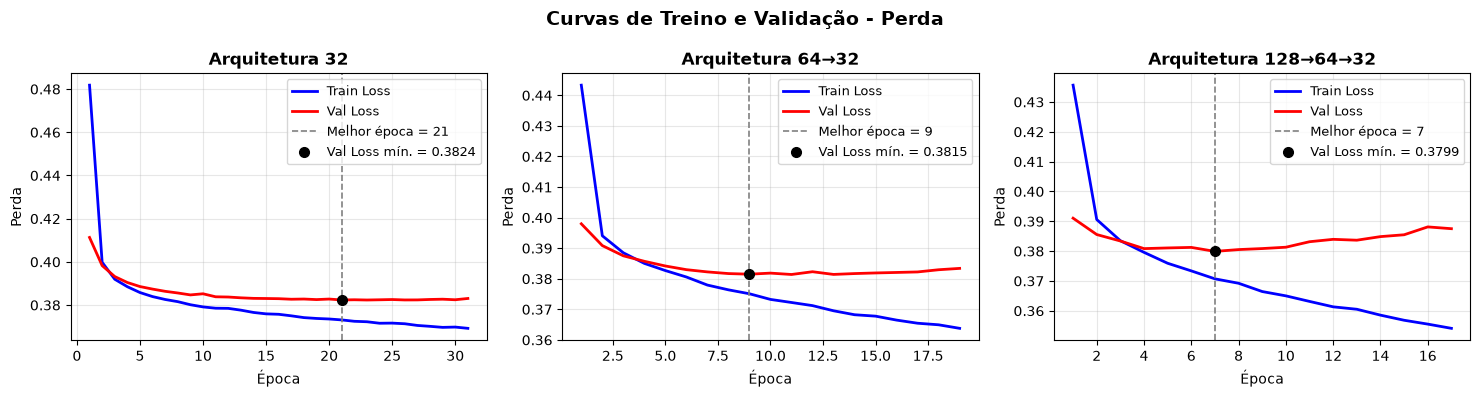


Observações sobre as curvas:
- Treino (azul) deve diminuir consistentemente.
- Validação (vermelho) deve acompanhar o treino inicialmente.
- Se validação aumentar enquanto treino diminui: possível overfitting.
- A linha tracejada marca a época cujos pesos foram restaurados; o painel de Val F1 por época está na seção 10.1.


In [11]:
# Cria figura com 3 subgráficos: um para cada arquitetura.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Itera sobre as 3 arquiteturas (perdas por época, época dos pesos restaurados e nome).
for idx, (losses_train, losses_val, best_ep, arch_name) in enumerate([
    (train_losses_1, val_losses_1, history_1['best_epoch'], '32'),
    (train_losses_2, val_losses_2, history_2['best_epoch'], '64→32'),
    (train_losses_3, val_losses_3, history_3['best_epoch'], '128→64→32')
]):
    # Seleciona o subgráfico atual (eixo 0, 1 ou 2).
    ax = axes[idx]
    # Gera eixo X: números de 1 até a última época treinada.
    epochs_range = range(1, len(losses_train) + 1)

    # Plota linha azul: perda de treino ao longo das épocas.
    ax.plot(epochs_range, losses_train, label='Train Loss', color='blue', linewidth=2)
    # Plota linha vermelha: perda de validação ao longo das épocas.
    ax.plot(epochs_range, losses_val, label='Val Loss', color='red', linewidth=2)
    # Desenha linha vertical tracejada na época dos pesos restaurados, com a época na legenda.
    ax.axvline(best_ep, color='gray', linestyle='--', linewidth=1.2, label=f'Melhor época = {best_ep}')
    # Marca com um ponto a val_loss da melhor época.
    ax.plot(best_ep, losses_val[best_ep - 1], 'o', color='black', markersize=7,
            # Rótulo do ponto com o valor da val_loss.
            label=f'Val Loss mín. = {losses_val[best_ep - 1]:.4f}')
    # Define nome do subgráfico (título).
    ax.set_title(f'Arquitetura {arch_name}', fontsize=12, fontweight='bold')
    # Define rótulo do eixo X (épocas).
    ax.set_xlabel('Época', fontsize=10)
    # Define rótulo do eixo Y (perda).
    ax.set_ylabel('Perda', fontsize=10)
    # Ativa legenda (mostra labels das linhas).
    ax.legend(fontsize=9)
    # Adiciona grid para melhor leitura.
    ax.grid(True, alpha=0.3)

# Define título geral da figura.
fig.suptitle('Curvas de Treino e Validação - Perda', fontsize=14, fontweight='bold')
# Ajusta espaçamento entre subgráficos.
plt.tight_layout()
# Exibe a figura.
plt.show()

# Exibe observações sobre as curvas.
print("\nObservações sobre as curvas:")
print("- Treino (azul) deve diminuir consistentemente.")
print("- Validação (vermelho) deve acompanhar o treino inicialmente.")
print("- Se validação aumentar enquanto treino diminui: possível overfitting.")
print("- A linha tracejada marca a época cujos pesos foram restaurados; o painel de Val F1 por época está na seção 10.1.")

## 10. Seleção rigorosa de arquitetura (várias seeds)

Funções novas em `src/models/selecao_arquitetura.py`.

- **10.1** Curvas dos 3 modelos treinados acima: perda com a melhor época marcada e Val F1 por época.
- **10.2** Resultados de 3 arquiteturas × 2 critérios de early stopping (`val_loss`, `val_f1`) × 5 seeds (0–4).
  Se `models/experiments/selecao_arquitetura/resultados_seeds.csv` e `historicos_seeds.json` existirem, são reaproveitados.
  Caso contrário, a célula treina as 30 execuções (cerca de 1h30 na GPU). Também é possível gerá-los antes, na raiz do projeto:
  `python -m src.models.selecao_arquitetura --etapa seeds`.
- **10.3** Média ± desvio e testes pareados (n=5: baixo poder estatístico).
- **10.4** Regra de decisão: maior val_F1 médio, salvo se uma arquitetura mais simples ficar a até 1 desvio padrão; nesse caso, a mais simples.
  O teste 2025 aparece só depois da escolha, para confirmá-la.

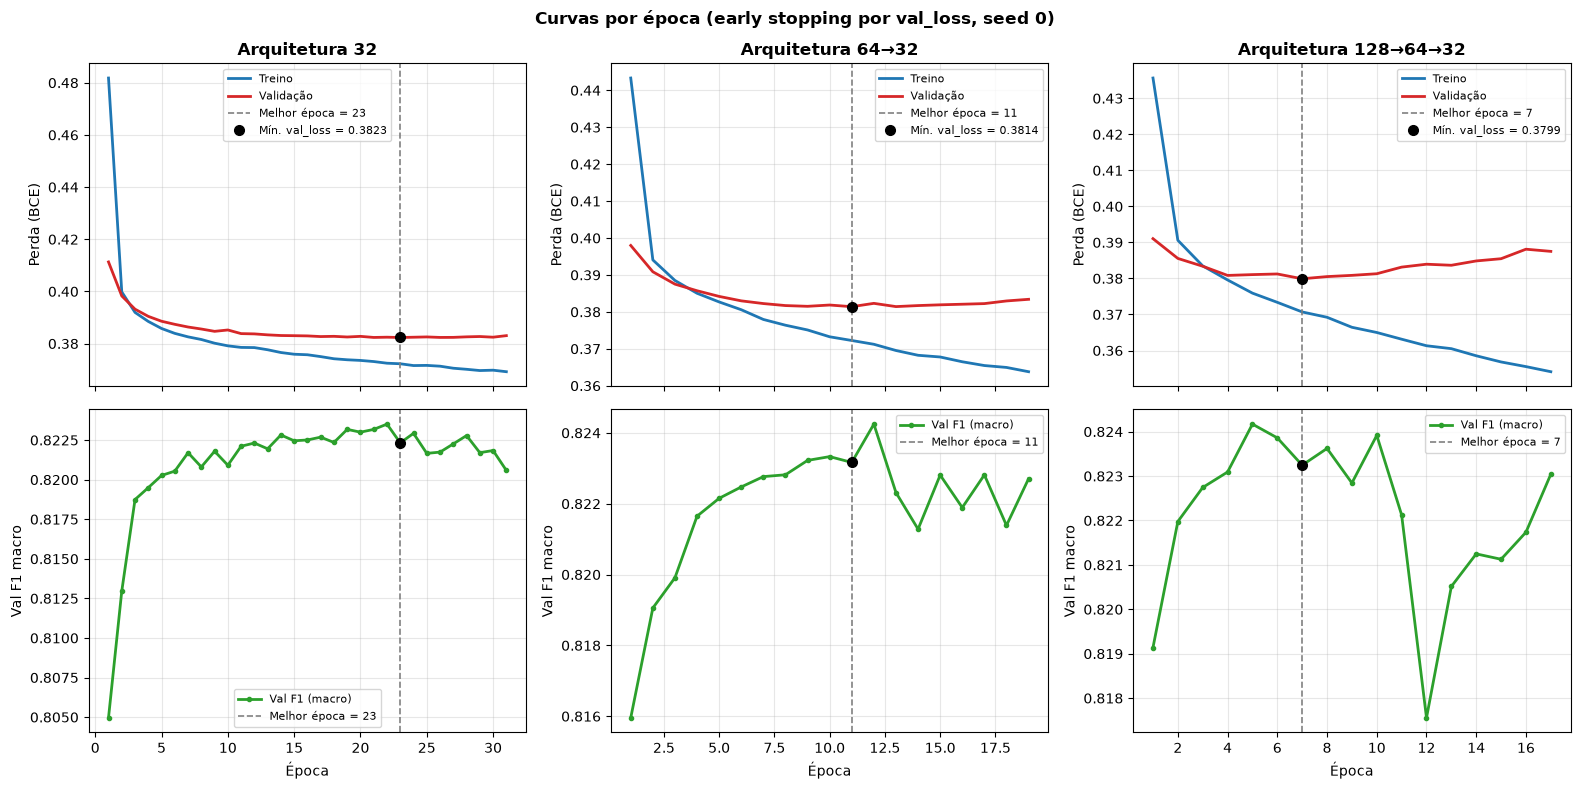

In [12]:
# Importa as funções novas de figuras e o nome das arquiteturas do módulo de seleção.
from src.models.selecao_arquitetura import figura_curvas, ARQUITETURAS
# O módulo fixa o backend 'Agg' (para rodar sem janela); restaura o backend inline para exibir as figuras aqui.
%matplotlib inline
# Monta o dicionário de históricos dos 3 modelos da seção 5–7 no formato 'arquitetura|monitor|seed'.
hist_original = {f'{nome}|val_loss|0': h for nome, h in zip(ARQUITETURAS, [history_1, history_2, history_3])}
# Gera a figura com perda (melhor época tracejada + ponto no mínimo) e Val F1 por época, sem salvar.
fig_orig = figura_curvas(hist_original, monitor='val_loss', seed=0)
# Exibe a figura no notebook.
plt.show()

In [13]:
# Importa as funções de execução, tabelas, testes e decisão do módulo de seleção.
from src.models.selecao_arquitetura import (executar_etapa_seeds, tabela_media_desvio, testes_pareados,
    # Continua a importação: regra de decisão, figuras e pastas de saída.
    regra_decisao, figura_comparacao, DIR_RESULTADOS, DIR_FIGURAS, MONITORES)
# Importa json para ler os históricos por época salvos pelo script.
import json
# Define o caminho do CSV de resultados por execução.
caminho_csv = DIR_RESULTADOS / 'resultados_seeds.csv'
# Define o caminho do JSON com os históricos por época.
caminho_hist = DIR_RESULTADOS / 'historicos_seeds.json'
# Verifica se o treino com várias seeds já foi feito (evita repetir ~1h30 de GPU).
if caminho_csv.exists() and caminho_hist.exists():
    # Lê os resultados por execução.
    df_seeds = pd.read_csv(caminho_csv)
    # Lê os históricos por época.
    hist_seeds = json.loads(caminho_hist.read_text(encoding='utf-8'))
# Caso contrário, executa as 30 execuções agora (grava o CSV e o JSON).
else:
    # Treina 3 arquiteturas × 2 critérios × 5 seeds.
    df_seeds, hist_seeds = executar_etapa_seeds()
# Mostra quantas execuções foram carregadas.
print(f'{len(df_seeds)} execuções em {caminho_csv}')

30 execuções em D:\Seguranca_Publica.InteligenteSP\models\experiments\selecao_arquitetura\resultados_seeds.csv


In [14]:
# Exibe a tabela média ± desvio (todas as métricas de validação vêm da melhor época).
display(tabela_media_desvio(df_seeds))
# Exibe os testes pareados de val_F1 por seed (t pareado e Wilcoxon; n=5, menor p possível no Wilcoxon = 0,0625).
display(testes_pareados(df_seeds).round(4))


,,melhor_epoca,val_loss,val_acc,val_f1,test_loss,test_acc,test_prec,test_rec,test_f1,n_parametros,tempo_treino_s
monitor,arquitetura,,,,,,,,,,,
val_loss,32,27.6 ± 3.9,0.3828 ± 0.0004,0.8333 ± 0.0007,0.8225 ± 0.0007,0.3817 ± 0.0004,0.8342 ± 0.0003,0.7679 ± 0.0018,0.7898 ± 0.0033,0.8231 ± 0.0004,61313 ± 0,231.1 ± 24.5
val_f1,32,28.4 ± 12.3,0.3833 ± 0.0005,0.8339 ± 0.0003,0.8236 ± 0.0003,0.3821 ± 0.0009,0.8343 ± 0.0007,0.7648 ± 0.0034,0.7960 ± 0.0050,0.8236 ± 0.0007,61313 ± 0,231.9 ± 68.1
val_loss,64→32,10.8 ± 1.3,0.3809 ± 0.0002,0.8344 ± 0.0004,0.8235 ± 0.0005,0.3801 ± 0.0002,0.8346 ± 0.0006,0.7704 ± 0.0034,0.7865 ± 0.0062,0.8232 ± 0.0008,124673 ± 0,162.6 ± 10.8
val_f1,64→32,7.6 ± 3.0,0.3826 ± 0.0012,0.8340 ± 0.0009,0.8238 ± 0.0005,0.3807 ± 0.0008,0.8345 ± 0.0008,0.7649 ± 0.0060,0.7971 ± 0.0099,0.8239 ± 0.0007,124673 ± 0,137.4 ± 23.0
val_loss,128→64→32,7.0 ± 1.2,0.3803 ± 0.0003,0.8343 ± 0.0005,0.8235 ± 0.0007,0.3799 ± 0.0004,0.8345 ± 0.0009,0.7698 ± 0.0029,0.7873 ± 0.0057,0.8232 ± 0.0011,255489 ± 0,163.1 ± 12.5
val_f1,128→64→32,6.6 ± 1.5,0.3804 ± 0.0004,0.8345 ± 0.0008,0.8240 ± 0.0004,0.3799 ± 0.0005,0.8350 ± 0.0003,0.7691 ± 0.0052,0.7907 ± 0.0096,0.8239 ± 0.0006,255489 ± 0,158.6 ± 14.6


,monitor,comparacao,dif_media,dif_desvio,b_vence_em,p_t_pareado,p_wilcoxon
0,val_loss,64→32 − 32,0.0010,0.0006,5/5,0.0227,0.0625
1,val_loss,128→64→32 − 32,0.0010,0.0008,4/5,0.0448,0.1250
2,val_loss,128→64→32 − 64→32,-0.0000,0.0004,3/5,0.9504,1.0000
3,val_f1,64→32 − 32,0.0003,0.0007,3/5,0.4701,0.4375
4,val_f1,128→64→32 − 32,0.0004,0.0007,4/5,0.2404,0.1875
5,val_f1,128→64→32 − 64→32,0.0002,0.0007,2/5,0.6430,0.8125


In [15]:
# Aplica a regra de decisão para cada critério de early stopping (usa só validação).
for monitor in MONITORES:
    # Calcula a arquitetura escolhida, as estatísticas e a justificativa.
    escolhida, est, motivo = regra_decisao(df_seeds, monitor)
    # Imprime a decisão e o motivo.
    print(f'[ES por {monitor}] escolhida: {escolhida}\n  {motivo}')
    # Exibe média, desvio e parâmetros por arquitetura.
    display(est.round(4))
    # Seleciona as execuções da arquitetura escolhida neste critério.
    sel = df_seeds[(df_seeds.monitor == monitor) & (df_seeds.arquitetura == escolhida)]
    # Mostra o teste 2025 apenas como confirmação, depois da escolha.
    print(f"  Confirmação no teste 2025: test_F1 = {sel.test_f1.mean():.4f} ± {sel.test_f1.std():.4f}\n")


[ES por val_loss] escolhida: 64→32
  64→32 tem o maior val_F1 médio e nenhuma mais simples fica a ≤ 1 desvio.


,media,desvio,params
arquitetura,,,
32,0.8225,0.0007,61313
64→32,0.8235,0.0005,124673
128→64→32,0.8235,0.0007,255489


  Confirmação no teste 2025: test_F1 = 0.8232 ± 0.0008

[ES por val_f1] escolhida: 32
  128→64→32 tem o maior val_F1 médio (0.8240), mas 32 fica a 0.0004, dentro de 1 desvio (0.0004); por parcimônia escolhe-se 32.


,media,desvio,params
arquitetura,,,
32,0.8236,0.0003,61313
64→32,0.8238,0.0005,124673
128→64→32,0.8240,0.0004,255489


  Confirmação no teste 2025: test_F1 = 0.8236 ± 0.0007



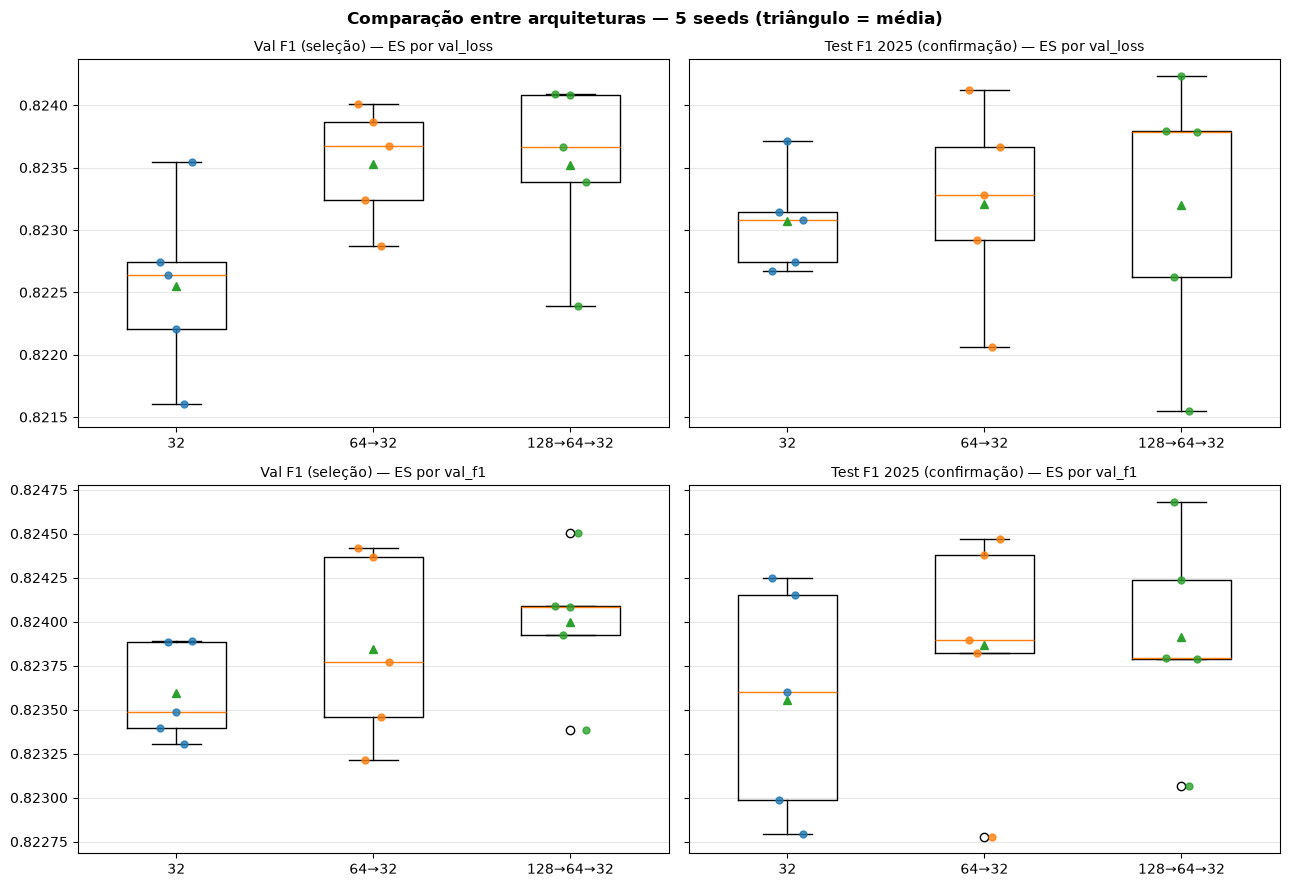

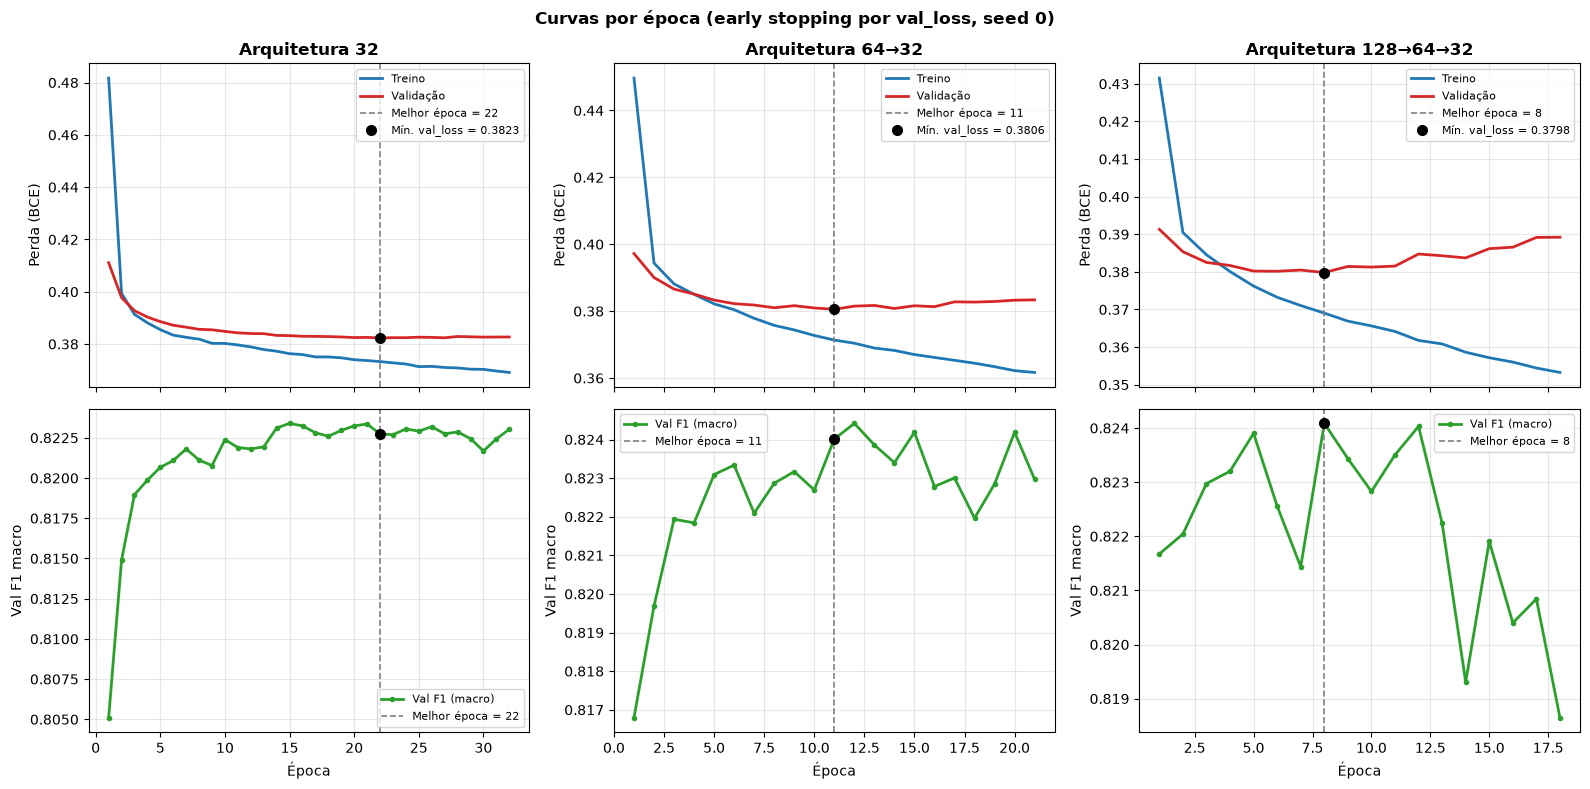

In [16]:
# Gera e salva o gráfico de pontos/boxplot de val_F1 e test_F1 por arquitetura.
figura_comparacao(df_seeds, caminho=DIR_FIGURAS / 'comparacao_seeds.png')
# Exibe a figura no notebook.
plt.show()
# Gera e salva as curvas por época da seed 0 (critério val_loss), com a melhor época marcada.
figura_curvas(hist_seeds, monitor='val_loss', seed=0, caminho=DIR_FIGURAS / 'curvas_perda.png')
# Exibe a figura no notebook.
plt.show()


## 11. Matriz de confusão do modelo escolhido (confirmação no teste 2025)

Arquitetura escolhida (ES por val_loss): 64→32
  64→32 tem o maior val_F1 médio e nenhuma mais simples fica a ≤ 1 desvio.
[Confirmação teste 2025] F1 macro 0.8232 | Acc 0.8346 | Prec(roubo) 0.7705 | Rec(roubo) 0.7863


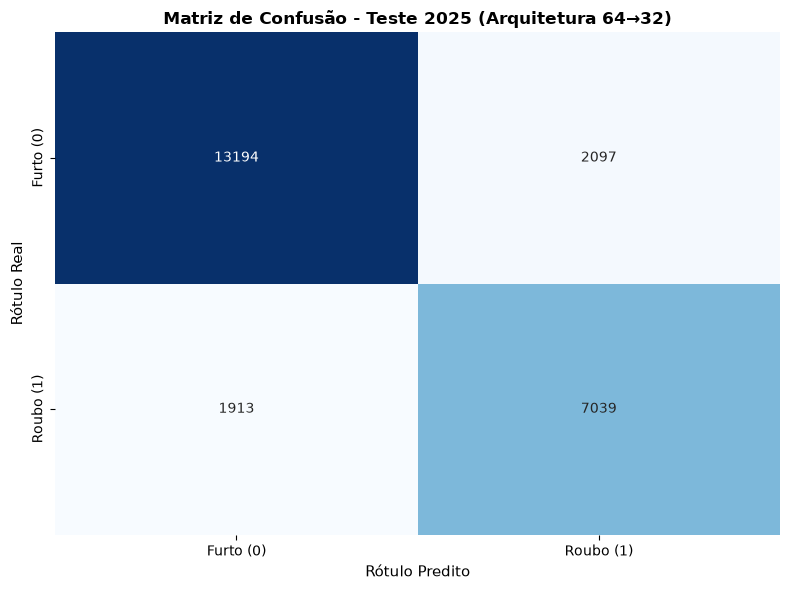


Relatório de classificação (teste 2025):
              precision    recall  f1-score   support

   Furto (0)       0.87      0.86      0.87     15291
   Roubo (1)       0.77      0.79      0.78      8952

    accuracy                           0.83     24243
   macro avg       0.82      0.82      0.82     24243
weighted avg       0.84      0.83      0.83     24243



In [17]:
# Importa a regra de decisão do módulo de seleção (usa apenas resultados de validação).
from src.models.selecao_arquitetura import regra_decisao, ARQUITETURAS
# Define o critério de early stopping padrão do projeto (o mesmo usado para treinar os modelos das seções 5–7).
CRITERIO_DECISAO = 'val_loss'
# Aplica a regra de parcimônia aos resultados das 5 seeds e obtém a arquitetura escolhida.
arq_escolhida, est_decisao, motivo_decisao = regra_decisao(df_seeds, CRITERIO_DECISAO)
# Mostra a arquitetura escolhida e a justificativa.
print(f"Arquitetura escolhida (ES por {CRITERIO_DECISAO}): {arq_escolhida}\n  {motivo_decisao}")

# Associa cada arquitetura ao modelo treinado nas seções 5–7 (early stopping por val_loss).
modelos_treinados = {'32': model_1, '64→32': model_2, '128→64→32': model_3}
# Associa cada arquitetura ao histórico de treino correspondente.
historicos_treinados = {'32': history_1, '64→32': history_2, '128→64→32': history_3}
# Seleciona o modelo da arquitetura escolhida.
best_model = modelos_treinados[arq_escolhida]
# Guarda a posição da arquitetura escolhida na tabela da seção 8.
best_arch_idx = list(modelos_treinados).index(arq_escolhida)

# Cria o TensorDataset do teste 2025 (arrays numpy → tensores).
test_dataset_2025 = TensorDataset(torch.tensor(X_test_2025, dtype=torch.float32),
                                  # Rótulos do teste 2025 como tensor float.
                                  torch.tensor(y_test_2025, dtype=torch.float32))
# Cria o DataLoader do teste sem embaralhar (matriz de confusão consistente).
test_loader_2025 = DataLoader(test_dataset_2025, batch_size=BATCH_SIZE, shuffle=False)

# Avalia o modelo escolhido no teste 2025, só depois da escolha (confirmação).
test_loss_best, test_acc_best, test_prec_best, test_rec_best, test_f1_best, y_preds, y_trues = avaliar(
    # Argumentos: modelo, dados de teste, perda e dispositivo.
    best_model, test_loader_2025, loss_fn, device)
# Exibe as métricas de confirmação.
print(f"[Confirmação teste 2025] F1 macro {test_f1_best:.4f} | Acc {test_acc_best:.4f} | "
      # Continua com precisão e recall da classe roubo.
      f"Prec(roubo) {test_prec_best:.4f} | Rec(roubo) {test_rec_best:.4f}")

# Calcula matriz de confusão: [Verdadeiro Neg, Falso Pos] / [Falso Neg, Verdadeiro Pos].
cm = confusion_matrix(y_trues, y_preds)

# Cria figura e eixo para exibir a matriz.
fig, ax = plt.subplots(figsize=(8, 6))
# Exibe heatmap da matriz de confusão (cores mais intensas = mais amostras).
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
            # Rótulos das colunas (classe prevista).
            xticklabels=['Furto (0)', 'Roubo (1)'],
            # Rótulos das linhas (classe real).
            yticklabels=['Furto (0)', 'Roubo (1)'])
# Define título com a arquitetura escolhida.
ax.set_title(f'Matriz de Confusão - Teste 2025 (Arquitetura {arq_escolhida})', fontsize=12, fontweight='bold')
# Define rótulo do eixo Y (rótulos reais).
ax.set_ylabel('Rótulo Real', fontsize=11)
# Define rótulo do eixo X (rótulos preditos).
ax.set_xlabel('Rótulo Predito', fontsize=11)
# Ajusta o espaçamento.
plt.tight_layout()
# Exibe figura.
plt.show()

# Calcula métricas por classe.
report = classification_report(y_trues, y_preds, target_names=['Furto (0)', 'Roubo (1)'])
# Exibe relatório de classificação (precisão, recall, F1 por classe).
print("\nRelatório de classificação (teste 2025):")
print(report)

## 12. Salvar o modelo escolhido

In [18]:
# Importa joblib para salvar o pré-processador.
import joblib
# Importa json para salvar mapeamento e metadados.
import json

# Cria pasta de modelos se não existir.
BEST_MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Define caminho completo onde o modelo será salvo.
model_path = BEST_MODEL_DIR / 'mlp_model.pth'
# Salva apenas os pesos (state_dict) do modelo escolhido em formato PyTorch.
torch.save(best_model.state_dict(), model_path)
# Exibe confirmação e caminho.
print(f"✓ Modelo escolhido ({arq_escolhida}) salvo em: {model_path}")

# Define caminho para salvar o pré-processador ajustado no treino.
preprocessor_path = BEST_MODEL_DIR / 'preprocessor.pkl'
# Salva o preprocessor (imputador, encoder, scaler) em arquivo pickle.
joblib.dump(preprocessor, preprocessor_path)
# Exibe confirmação.
print(f"✓ Preprocessor salvo em: {preprocessor_path}")

# Define o mapeamento das classes: 0 = Furto, 1 = Roubo (referência para inferência).
label_mapping = {0: 'Furto', 1: 'Roubo'}
# Define caminho para mapeamento de labels.
mapping_path = BEST_MODEL_DIR / 'label_mapping.json'
# Abre arquivo em modo escrita, em UTF-8.
with open(mapping_path, 'w', encoding='utf-8') as f:
    # Escreve dicionário em formato JSON.
    json.dump(label_mapping, f, indent=2)
# Exibe confirmação.
print(f"✓ Label mapping salvo em: {mapping_path}")

# Monta os metadados do modelo (arquitetura, hiperparâmetros, critério de escolha e confirmação).
metadata = {
    # Arquitetura escolhida pela regra de decisão.
    'architecture': arq_escolhida,
    # Tamanhos das camadas ocultas (necessário para reconstruir a rede na inferência).
    'hidden_sizes': ARQUITETURAS[arq_escolhida],
    # Número de features de entrada.
    'n_features': int(n_features),
    # Número de parâmetros treináveis.
    'n_parameters': int(sum(p.numel() for p in best_model.parameters() if p.requires_grad)),
    # Ativação e dropout das camadas ocultas.
    'activation': 'relu',
    # Taxa de dropout usada no treino.
    'dropout': 0.2,
    # Otimizador e hiperparâmetros.
    'optimizer': 'AdamW',
    # Taxa de aprendizado.
    'learning_rate': LEARNING_RATE,
    # Decaimento de pesos.
    'weight_decay': 1e-4,
    # Tamanho de batch.
    'batch_size': BATCH_SIZE,
    # Teto de épocas.
    'max_epochs': EPOCHS,
    # Época cujos pesos foram restaurados.
    'best_epoch': int(historicos_treinados[arq_escolhida]['best_epoch']),
    # Configuração do early stopping.
    'early_stopping': {'monitor': 'val_loss', 'mode': 'min', 'patience': 10, 'min_delta': 1e-4},
    # Limiar de decisão sobre a probabilidade de roubo.
    'threshold': 0.5,
    # Regra e justificativa da escolha (somente validação).
    'selection_rule': motivo_decisao,
    # Val F1 macro médio e desvio nas 5 seeds.
    'val_f1_seeds_mean': float(est_decisao.loc[arq_escolhida, 'media']),
    # Desvio padrão do Val F1 nas 5 seeds.
    'val_f1_seeds_std': float(est_decisao.loc[arq_escolhida, 'desvio']),
    # Acurácia no teste 2025 do modelo salvo (confirmação).
    'test_2025_accuracy': float(test_acc_best),
    # F1 macro no teste 2025 do modelo salvo (confirmação).
    'test_2025_f1_macro': float(test_f1_best),
}
# Define caminho para metadados.
metadata_path = BEST_MODEL_DIR / 'metadata.json'
# Abre arquivo em modo escrita, em UTF-8.
with open(metadata_path, 'w', encoding='utf-8') as f:
    # Escreve metadados em JSON mantendo caracteres como '→'.
    json.dump(metadata, f, indent=2, ensure_ascii=False)
# Exibe confirmação.
print(f"✓ Metadata salvo em: {metadata_path}")

# Exibe mensagem final de sucesso.
print("\n" + "="*60)
print("✓ ETAPA 2 CONCLUÍDA COM SUCESSO")
print(f"  Modelo escolhido: Arquitetura {arq_escolhida}")
print(f"  Salvo em: {BEST_MODEL_DIR}")
print("="*60)

✓ Modelo escolhido (64→32) salvo em: D:\Seguranca_Publica.InteligenteSP\models\best\mlp_model.pth
✓ Preprocessor salvo em: D:\Seguranca_Publica.InteligenteSP\models\best\preprocessor.pkl
✓ Label mapping salvo em: D:\Seguranca_Publica.InteligenteSP\models\best\label_mapping.json
✓ Metadata salvo em: D:\Seguranca_Publica.InteligenteSP\models\best\metadata.json

✓ ETAPA 2 CONCLUÍDA COM SUCESSO
  Modelo escolhido: Arquitetura 64→32
  Salvo em: D:\Seguranca_Publica.InteligenteSP\models\best


## 13. Justificativa da escolha

### Critério de seleção: **F1-score macro em validação, médio em 5 seeds**

**Por que F1 macro?**
- O conjunto é levemente desbalanceado (mais furtos que roubos).
- O F1 macro dá peso igual às duas classes e não favorece a classe majoritária.

### Por que várias seeds?
Na execução única (seção 8), as três arquiteturas ficaram a cerca de 0,002 de F1 entre si, e a 128→64→32 parecia a melhor.
Com 5 seeds (seção 10), essa diferença fica dentro da variação entre execuções:

| ES por val_loss | Val F1 (média ± dp) | Test F1 2025 | Parâmetros |
|---|---|---|---|
| 32 | 0,8225 ± 0,0007 | 0,8231 ± 0,0004 | 61.313 |
| 64→32 | 0,8235 ± 0,0005 | 0,8232 ± 0,0008 | 124.673 |
| 128→64→32 | 0,8235 ± 0,0007 | 0,8232 ± 0,0011 | 255.489 |

- 64→32 e 128→64→32 empatam em validação (diferença média 0,0000; p = 0,95 no t pareado).
- A 32 fica cerca de 0,001 abaixo; o t pareado indica diferença (p ≈ 0,02–0,04), mas o Wilcoxon não (p ≥ 0,0625, o menor possível com n = 5). Com n = 5, o poder é baixo.
- A 128→64→32 atinge a melhor época mais cedo (≈ 7) e a val_loss sobe mais depois disso (overfitting mais forte).
- Com regularização extra (dropout 0,3/0,5, lr menor; 9 execuções da grade opcional), a 128→64→32 não superou as demais.

### Decisão
Regra: maior val_F1 médio; se uma arquitetura mais simples ficar a até 1 desvio padrão, escolhe-se a mais simples. O teste 2025 só confirma.
A célula da seção 11 aplica a regra (early stopping por val_loss, o padrão) e, com os resultados atuais, escolhe a **64→32**: mesmo desempenho da 128→64→32 com metade dos parâmetros.
Com early stopping por val_f1, a mesma regra escolheria a 32. Em ambos os casos, a rede de três camadas não se justifica.

O teste 2026 continua reservado para a avaliação final.